In [2]:
from google.colab import files
files.upload()

Saving ai4i2020.csv to ai4i2020.csv


{'ai4i2020.csv': b'\xef\xbb\xbfUDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF\r\n1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0\r\n2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0\r\n3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0\r\n4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0\r\n5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0\r\n6,M14865,M,298.1,308.6,1425,41.9,11,0,0,0,0,0,0\r\n7,L47186,L,298.1,308.6,1558,42.4,14,0,0,0,0,0,0\r\n8,L47187,L,298.1,308.6,1527,40.2,16,0,0,0,0,0,0\r\n9,M14868,M,298.3,308.7,1667,28.6,18,0,0,0,0,0,0\r\n10,M14869,M,298.5,309,1741,28.0,21,0,0,0,0,0,0\r\n11,H29424,H,298.4,308.9,1782,23.9,24,0,0,0,0,0,0\r\n12,H29425,H,298.6,309.1,1423,44.3,29,0,0,0,0,0,0\r\n13,M14872,M,298.6,309.1,1339,51.1,34,0,0,0,0,0,0\r\n14,M14873,M,298.6,309.2,1742,30.0,37,0,0,0,0,0,0\r\n15,L47194,L,298.6,309.2,2035,19.6,40,0,0,0,0,0,0\r\n16,L47195,L,298.6,309.2,1542,48.4,42,0,0,0,0,0,0\r\

<h1>1. Base de dados</h1>
<p>Base AI4I 2020 Predictive Maintenance (UCI Machine Learning Repository, acesso em 26/10/2026). Contém 10.000 registros de máquinas industriais com temperaturas, rotação, torque e desgaste da ferramenta. Como o trabalho pede de 100 a 200 registros, foi sorteada uma amostra aleatória de 150 linhas.</p>

In [3]:
import pandas as pd

df = pd.read_csv("ai4i2020.csv")
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

<p>Não há valores ausentes: todas as 14 colunas têm 10.000 valores não nulos. Foram analisadas 5 variáveis quantitativas: temperatura do ar, temperatura do processo, rotação, torque e desgaste da ferramenta.</p>



In [6]:
amostra = df.sample(n=150, random_state=42)
print(amostra.shape)
amostra.head()

(150, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
6252,6253,L53432,L,300.8,310.3,1538,36.1,198,0,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
1731,1732,M16591,M,298.3,307.9,1485,42.0,117,0,0,0,0,0,0
4742,4743,L51922,L,303.3,311.3,1592,33.7,14,0,0,0,0,0,0
4521,4522,L51701,L,302.4,310.4,1865,23.9,129,0,0,0,0,0,0


<p>Amostra aleatória de 150 registros, com random_state=42 para que o sorteio seja reproduzível.</p>

<h1>2. Média, mediana e moda</h1>

In [7]:
colunas = ["Air temperature [K]", "Process temperature [K]",
           "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

print(amostra[colunas].mean())
print(amostra[colunas].median())
print(amostra[colunas].mode())

Air temperature [K]         300.085333
Process temperature [K]     310.093333
Rotational speed [rpm]     1517.693333
Torque [Nm]                  40.404667
Tool wear [min]              98.246667
dtype: float64
Air temperature [K]         300.15
Process temperature [K]     310.30
Rotational speed [rpm]     1504.00
Torque [Nm]                  40.35
Tool wear [min]              98.00
dtype: float64
   Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0                298.8                    311.2                    1447   
1                  NaN                      NaN                    1763   

   Torque [Nm]  Tool wear [min]  
0         40.8              0.0  
1          NaN              NaN  




<p>Média e mediana são muito próximas em quase todas as variáveis, o que indica distribuições equilibradas. A exceção é a rotação, cuja média (1517,7 rpm) fica acima da mediana (1504 rpm), sinal de valores altos puxando a média. A moda é pouco informativa nas variáveis contínuas, mas no desgaste vale 0, ou seja, muitas ferramentas novas.</p>


<h1>3. Quartis e dispersão</h1>

In [8]:
print(amostra[colunas].quantile([0.25, 0.5, 0.75]))

      Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0.25              298.600                  308.825                 1431.25   
0.50              300.150                  310.300                 1504.00   
0.75              301.675                  311.200                 1578.00   

      Torque [Nm]  Tool wear [min]  
0.25       34.300             34.0  
0.50       40.350             98.0  
0.75       45.975            154.0  


In [9]:
q = amostra[colunas].quantile([0.25, 0.75])
iqr = q.loc[0.75] - q.loc[0.25]
print(iqr)

Air temperature [K]          3.075
Process temperature [K]      2.375
Rotational speed [rpm]     146.750
Torque [Nm]                 11.675
Tool wear [min]            120.000
dtype: float64


<p>Foram usados os quartis Q1, Q2 (igual à mediana) e Q3, e o IQR (Q3 − Q1) como medida de dispersão. O desgaste é a variável mais dispersa (IQR de 120 min); as temperaturas são as mais concentradas.</p>

<h1> 4. Histogramas</h1>

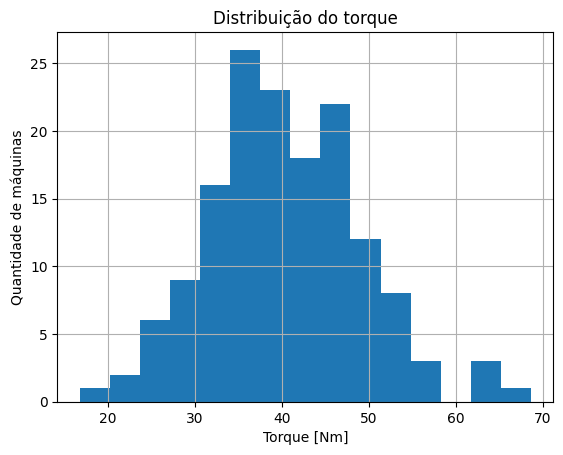

In [10]:
import matplotlib.pyplot as plt

amostra["Torque [Nm]"].hist(bins=15)
plt.title("Distribuição do torque")
plt.xlabel("Torque [Nm]")
plt.ylabel("Quantidade de máquinas")
plt.show()

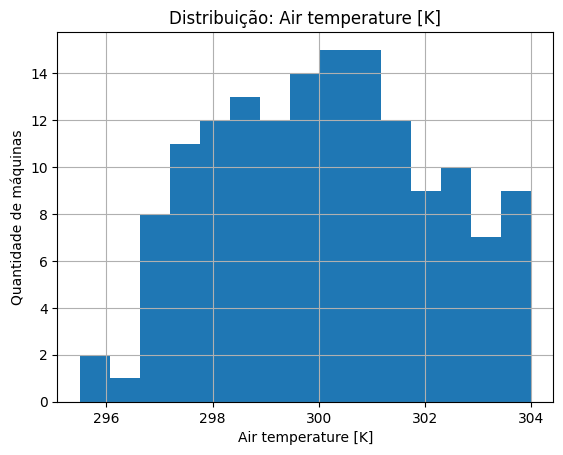

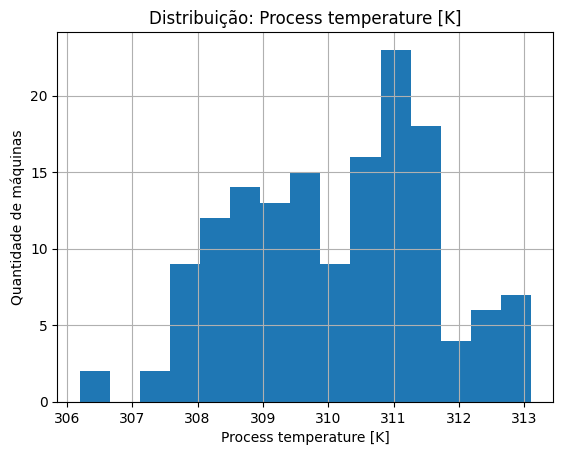

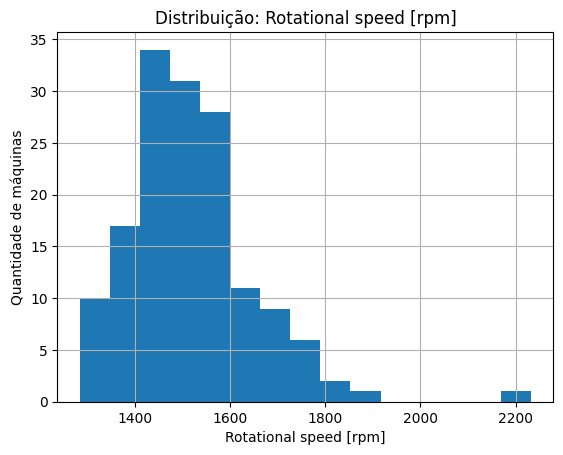

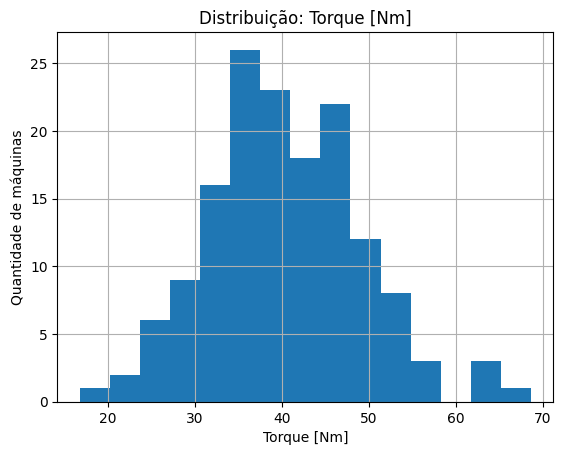

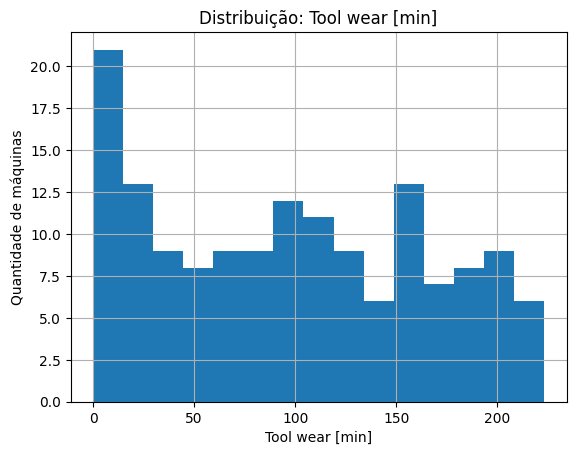

In [13]:
for col in colunas:
    amostra[col].hist(bins=15)
    plt.title(f"Distribuição: {col}")
    plt.xlabel(col)
    plt.ylabel("Quantidade de máquinas")
    plt.show()

<p> O torque tem forma de sino, com alguns valores altos atípicos (acima de 60 Nm). A rotação tem cauda à direita, com uma máquina atípica perto de 2200 rpm. O desgaste é próximo de uniforme, com muitas ferramentas novas. As temperaturas se concentram em faixas estreitas.</p>

<h1> 5. Dispersão e correlação</h1>

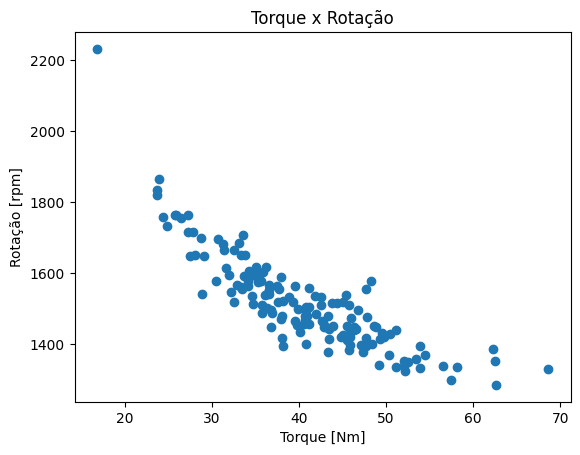

-0.8610954940654575


In [14]:
plt.scatter(amostra["Torque [Nm]"], amostra["Rotational speed [rpm]"])
plt.title("Torque x Rotação")
plt.xlabel("Torque [Nm]")
plt.ylabel("Rotação [rpm]")
plt.show()

print(amostra["Torque [Nm]"].corr(amostra["Rotational speed [rpm]"]))

In [15]:
print(amostra[colunas].corr())


                         Air temperature [K]  Process temperature [K]  \
Air temperature [K]                 1.000000                 0.873135   
Process temperature [K]             0.873135                 1.000000   
Rotational speed [rpm]              0.113544                 0.101727   
Torque [Nm]                        -0.115294                -0.119972   
Tool wear [min]                     0.044218                 0.078800   

                         Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
Air temperature [K]                    0.113544    -0.115294         0.044218  
Process temperature [K]                0.101727    -0.119972         0.078800  
Rotational speed [rpm]                 1.000000    -0.861095        -0.121811  
Torque [Nm]                           -0.861095     1.000000         0.075166  
Tool wear [min]                       -0.121811     0.075166         1.000000  


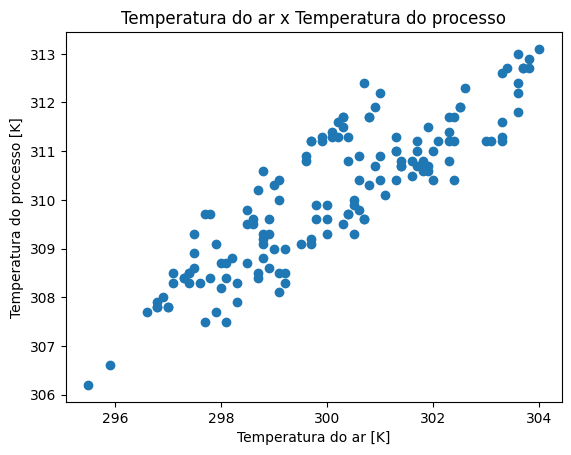

In [16]:
plt.scatter(amostra["Air temperature [K]"], amostra["Process temperature [K]"])
plt.title("Temperatura do ar x Temperatura do processo")
plt.xlabel("Temperatura do ar [K]")
plt.ylabel("Temperatura do processo [K]")
plt.show()

<p> Torque e rotação têm correlação negativa forte (r = −0,86), e as temperaturas do ar e do processo têm correlação positiva forte (r = 0,87). As demais correlações são fracas (|r| < 0,13). Correlação não demonstra causalidade.</p>

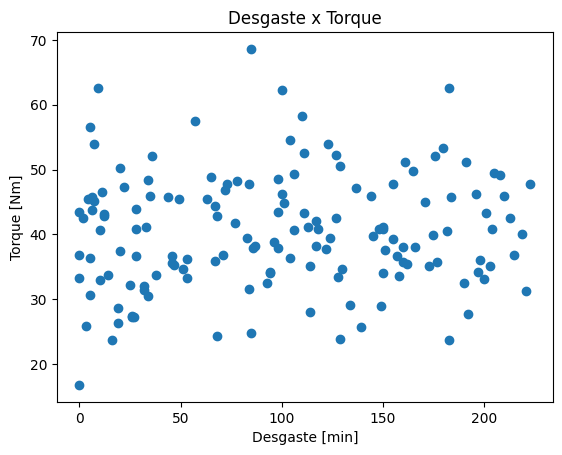

In [17]:
plt.scatter(amostra["Tool wear [min]"], amostra["Torque [Nm]"])
plt.title("Desgaste x Torque")
plt.xlabel("Desgaste [min]")
plt.ylabel("Torque [Nm]")
plt.show()

<p>O desgaste não tem relação linear visível com o torque (r = 0,08): os pontos se espalham sem padrão.</p>

In [18]:
amostra.to_csv("amostra_ai4i_150.csv", index=False)

<p>A amostra de 150 registros foi salva em amostra_ai4i_150.csv.</p>